In [15]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [29]:
datafr = pd.read_csv('AvoidanceSummary.csv')
datafr = datafr.drop('LTM_y', 1)
datafr = datafr.drop('LTM_n', 1)
datafr

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_84672/3351693519.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  datafr = datafr.drop('LTM_y', 1)
/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_84672/3351693519.py:3: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  datafr = datafr.drop('LTM_n', 1)


,Mock CS-,Mock CS+,SFC CS-,SFC CS+,SFC Cre+ CS-,SCF Cre+ CS+
0,0,0,8,0,6,6
1,0,0,8,0,6,6
2,0,0,8,0,6,6
3,0,0,8,0,6,6
4,0,0,8,0,5,6
5,0,0,9,0,5,5
6,0,0,9,1,5,5
7,0,0,9,1,4,4
8,0,0,7,1,4,7
9,0,0,7,1,0,0


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


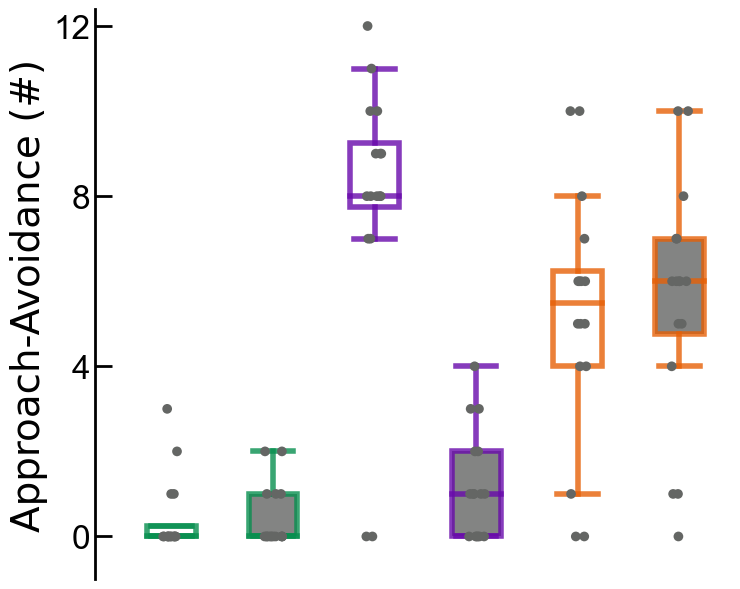

In [43]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


text_boxplot = ['','***','****']

colors = ["#646664","#646664","#646664","#646664","#646664","#646664"]
colors_boxplot = ['#078f4f', "#078f4f",'#680aab', "#680aab",'#e66007', "#e66007"]

ax = sns.stripplot(
    data=datafr,
    size=7,
    palette=colors,
    jitter=0.09
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=datafr,
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i]  
    patch.set_edgecolor(col)
    patch.set_facecolor('None')    
    if (i%2==1):
        patch.set_facecolor(colors[1])
        
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        

        
#END CHANGE BOXPLOT STYLE

plt.legend([],[], frameon=False)

ax.set_xticks([])
ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Approach-Avoidance (#)', fontsize = 28)

ax.set_ylim([-1,12.4])
ax.set_xlim([-0.75,5.5])

ax.set_yticks([0,4,8,12], fontname='Arial')
ax.set_yticklabels(['0','4','8','12'],fontname='Arial')

# ax.set_xlim([-0.45,3.5])

#significance(ax,2.5,1,datafr['Mock CS-'].max(),text=text_boxplot[2])
#significance(ax,6.5,1,datafr['Mock CS-'].max(),text=text_boxplot[1])

ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)


fig = ax.get_figure()

adjust_box_widths(fig, 0.6)
fig.set_size_inches(7.5,6)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_SummaryAvoidance.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig_SummaryAvoidance.eps', format='eps')